# Intenção de compra em loja virtual — Online Shoppers Purchasing Intention

**Disciplina:** Introdução ao Aprendizado de Máquina · IFSP Campinas · ADS
**Integrantes:** Melissa Batista Junqueira · Rafaela Laryssa Mello · Sophia Ferreira Boonen

**Problema:** Prever se uma sessão de navegação em uma loja virtual termina em compra (`purchase`), a partir de
informações de navegação, origem do tráfego, dispositivo e período.

**Roteiro do notebook**

1. Base e preparação (origem, tipos, limpeza, faltantes e outliers)
2. Análise exploratória (11 perguntas, 5 tipos de gráfico)
3. Modelagem (baseline + 3 técnicas, validação, vazamento, métricas, busca de hiperparâmetros)
4. Resultados
5. Conclusões, limitações e melhorias

## 0. Configuração e reprodutibilidade

- `random_state` fixado em **42** em todas as etapas aleatórias.
- Os arquivos são lidos de forma **relativa**: primeiro da pasta `data/`, depois da pasta do notebook.
  Se nenhuma das duas existir e o notebook estiver no Google Colab, o Google Drive é montado e a pasta
  `Colab Notebooks/Online_Shoppers` é usada.

In [28]:
import warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             make_scorer, precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
COR_NAO, COR_SIM = "#7A8CA5", "#E07B39"          # não comprou / comprou
PALETA = {"Não comprou": COR_NAO, "Comprou": COR_SIM}

In [29]:
def localizar_dados():
    """Procura os CSVs em caminhos relativos; no Colab, usa o Drive como alternativa."""
    arquivo = "online_shoppers_train.csv"
    for pasta in (Path("data"), Path(".")):
        if (pasta / arquivo).exists():
            return pasta
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except ImportError:
        pass
    pasta = Path("/content/drive/MyDrive/Colab Notebooks/Online_Shoppers")
    if (pasta / arquivo).exists():
        return pasta
    raise FileNotFoundError("Coloque online_shoppers_train.csv e online_shoppers_test.csv na pasta data/ "
                            "(ou ao lado do notebook).")

DATA_DIR = localizar_dados()
print("Dados lidos de:", DATA_DIR.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dados lidos de: /content/drive/MyDrive/Colab Notebooks/Online_Shoppers


## 1. Base e preparação

### 1.1 Origem e descrição da base

- **Fonte:** UCI Machine Learning Repository — *Online Shoppers Purchasing Intention Dataset*
  (Sakar & Kastro, 2018; licença CC BY 4.0). https://doi.org/10.24432/C5F88Q
- **Unidade de observação:** cada linha é **uma sessão** em uma loja virtual (um único comércio eletrônico, cerca de um ano).
- **Divisão fornecida pelo professor:** 9.864 sessões de treino e 2.466 de teste. A divisão é preservada.
- **Tarefa:** classificação binária. **Alvo:** `purchase` (`yes` = a sessão terminou em compra).

| Variável | Tipo | Descrição |
| --- | --- | --- |
| `administrative_pages`, `informational_pages`, `product_related_pages` | numérica (contagem) | Páginas visitadas em cada categoria. |
| `administrative_duration`, `informational_duration`, `product_related_duration` | numérica (tempo) | Tempo total em cada categoria de página. |
| `bounce_rate`, `exit_rate` | numérica (taxa, 0–1) | Taxas médias de rejeição e de saída das páginas da sessão. |
| `page_value` | numérica | Valor médio das páginas visitadas antes de transações. |
| `special_day` | numérica (0–1) | Proximidade da visita a uma data comercial especial. |
| `month` | categórica ordinal | Mês da sessão. |
| `operating_system`, `browser`, `region`, `traffic_type` | categórica nominal (código anonimizado) | Não são grandezas ordenadas. |
| `visitor_type` | categórica | `new`, `returning` ou `other`. |
| `weekend` | binária | Sessão em fim de semana. |
| `purchase` | **alvo** | A sessão terminou em compra? |

In [30]:
treino_raw = pd.read_csv(DATA_DIR / "online_shoppers_train.csv")
teste_raw = pd.read_csv(DATA_DIR / "online_shoppers_test.csv")

print(f"Treino: {treino_raw.shape[0]} linhas x {treino_raw.shape[1]} colunas")
print(f"Teste:  {teste_raw.shape[0]} linhas x {teste_raw.shape[1]} colunas")
treino_raw.head()

Treino: 9864 linhas x 18 colunas
Teste:  2466 linhas x 18 colunas


,administrative_pages,administrative_duration,informational_pages,informational_duration,product_related_pages,product_related_duration,bounce_rate,exit_rate,page_value,special_day,month,operating_system,browser,region,traffic_type,visitor_type,weekend,purchase
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,feb,os_1,browser_1,region_1,traffic_1,returning,no,no
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,feb,os_2,browser_2,region_1,traffic_2,returning,no,no
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,feb,os_4,browser_1,region_9,traffic_3,returning,no,no
3,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,feb,os_3,browser_3,region_1,traffic_4,returning,yes,no
4,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,feb,os_2,browser_2,region_1,traffic_3,returning,no,no


In [31]:
treino_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9864 entries, 0 to 9863
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   administrative_pages      9864 non-null   int64  
 1   administrative_duration   9864 non-null   float64
 2   informational_pages       9864 non-null   int64  
 3   informational_duration    9864 non-null   float64
 4   product_related_pages     9864 non-null   int64  
 5   product_related_duration  9864 non-null   float64
 6   bounce_rate               9864 non-null   float64
 7   exit_rate                 9864 non-null   float64
 8   page_value                9864 non-null   float64
 9   special_day               9864 non-null   float64
 10  month                     9864 non-null   object 
 11  operating_system          9864 non-null   object 
 12  browser                   9864 non-null   object 
 13  region                    9864 non-null   object 
 14  traffic_

### 1.2 Qualidade dos dados: faltantes, valores inválidos e inconsistências

In [32]:
suspeitos = ["", " ", "NA", "N/A", "na", "nan", "NaN", "null", "NULL", "None", "?", "-", "unknown", "Unknown"]

print("Nulos (treino):", treino_raw.isna().sum().sum(), "| (teste):", teste_raw.isna().sum().sum())
print("Textos que representam faltante (treino):", treino_raw.isin(suspeitos).sum().sum(),
      "| (teste):", teste_raw.isin(suspeitos).sum().sum())

categoricas_raw = ["month", "operating_system", "browser", "region", "traffic_type", "visitor_type", "weekend", "purchase"]
for c in categoricas_raw:
    print(f"\n{c}: {treino_raw[c].value_counts().to_dict()}")

Nulos (treino): 0 | (teste): 0
Textos que representam faltante (treino): 0 | (teste): 0

month: {'may': 2716, 'nov': 2410, 'mar': 1497, 'dec': 1411, 'oct': 427, 'sep': 358, 'jul': 340, 'aug': 327, 'jun': 233, 'feb': 145}

operating_system: {'os_2': 5275, 'os_1': 2091, 'os_3': 2034, 'os_4': 368, 'os_8': 70, 'os_6': 18, 'os_7': 4, 'os_5': 4}

browser: {'browser_2': 6339, 'browser_1': 1966, 'browser_4': 597, 'browser_5': 383, 'browser_6': 149, 'browser_10': 132, 'browser_8': 112, 'browser_3': 80, 'browser_13': 52, 'browser_7': 39, 'browser_12': 10, 'browser_11': 4, 'browser_9': 1}

region: {'region_1': 3788, 'region_3': 1947, 'region_4': 936, 'region_2': 922, 'region_6': 645, 'region_7': 604, 'region_9': 429, 'region_8': 338, 'region_5': 255}

traffic_type: {'traffic_2': 3158, 'traffic_1': 1925, 'traffic_3': 1643, 'traffic_4': 854, 'traffic_13': 584, 'traffic_10': 370, 'traffic_6': 362, 'traffic_8': 277, 'traffic_11': 197, 'traffic_5': 194, 'traffic_20': 162, 'traffic_9': 38, 'traffic_7':

In [33]:
num = treino_raw.select_dtypes("number")

print("Colunas numéricas com valores negativos:", (num < 0).any().loc[lambda s: s].index.tolist() or "nenhuma")
print("Taxas fora de [0, 1]:", ((treino_raw.bounce_rate > 1) | (treino_raw.exit_rate > 1)).sum())
print("special_day fora de [0, 1]:", ((treino_raw.special_day < 0) | (treino_raw.special_day > 1)).sum())

# Duração > 0 com zero páginas seria contraditório
for tipo in ["administrative", "informational", "product_related"]:
    n = ((treino_raw[f"{tipo}_duration"] > 0) & (treino_raw[f"{tipo}_pages"] == 0)).sum()
    print(f"{tipo}: duração > 0 com 0 páginas -> {n}")

# Casos que parecem estranhos, mas são plausíveis (apenas contamos)
print("\nbounce_rate > exit_rate:", (treino_raw.bounce_rate > treino_raw.exit_rate + 1e-9).sum())
sem_paginas = treino_raw[["administrative_pages", "informational_pages", "product_related_pages"]].sum(axis=1) == 0
print("Sessões sem nenhuma página:", sem_paginas.sum())

Colunas numéricas com valores negativos: nenhuma
Taxas fora de [0, 1]: 0
special_day fora de [0, 1]: 0
administrative: duração > 0 com 0 páginas -> 0
informational: duração > 0 com 0 páginas -> 0
product_related: duração > 0 com 0 páginas -> 0

bounce_rate > exit_rate: 150
Sessões sem nenhuma página: 4


In [34]:
print("Duplicados exatos no treino:", treino_raw.duplicated().sum())
print("Duplicados exatos no teste: ", teste_raw.duplicated().sum())

print("\nClasse das linhas duplicadas (treino):")
print(treino_raw[treino_raw.duplicated()]["purchase"].value_counts())

# Existe alguma combinação de atributos idêntica, mas com alvo diferente? (conflito)
feats = [c for c in treino_raw.columns if c != "purchase"]
conflito = treino_raw.groupby(feats)["purchase"].nunique().gt(1).sum()
print("\nGrupos com atributos iguais e alvo diferente:", conflito)

Duplicados exatos no treino: 98
Duplicados exatos no teste:  27

Classe das linhas duplicadas (treino):
purchase
no    98
Name: count, dtype: int64

Grupos com atributos iguais e alvo diferente: 0


**Conclusões da inspeção**

- Não há valores nulos nem textos que representem dados faltantes.
- Não há valores negativos, taxas fora de [0, 1] nem duração positiva com zero páginas.
- Há **linhas duplicadas exatas no treino**, todas da classe `no` e sem conflito de alvo. São sessões idênticas
  (em geral muito curtas) e a repetição não acrescenta informação nova ao treino.
- `bounce_rate > exit_rate`, páginas com duração zero e sessões sem páginas são **plausíveis**: as taxas são médias
  por página e uma página pode ser visitada de forma muito rápida. Por isso **não são removidos**.

### 1.3 Ajustes iniciais (tipos, duplicatas, valores inválidos)

Decisões aplicadas pela função `limpar()`:

1. Padronizar textos (minúsculas, sem espaços sobrando).
2. Definir os tipos corretos: contagens como inteiros, tempos e taxas como `float`.
3. Converter `purchase` e `weekend` de `yes`/`no` para `1`/`0`.
4. Manter `operating_system`, `browser`, `region` e `traffic_type` como **categorias** (não são grandezas ordenadas).
   `month` vira categoria ordenada, de janeiro a dezembro.
5. Remover duplicados exatos **somente no treino**. O teste é mantido intacto, pois representa a avaliação final
   e tem de permanecer idêntico ao fornecido (ele tem 27 linhas duplicadas, que são mantidas).

Nenhuma dessas operações aprende parâmetros a partir dos dados (não há média, escala ou categoria "aprendida"), portanto
podem ser aplicadas ao treino e ao teste **separadamente**, sem vazamento. As transformações que aprendem algo
(padronização, codificação) ficam dentro dos *pipelines* da seção 3.

In [35]:
NUMERICAS_INT = ["administrative_pages", "informational_pages", "product_related_pages"]
NUMERICAS_FLOAT = ["administrative_duration", "informational_duration", "product_related_duration",
                   "bounce_rate", "exit_rate", "page_value", "special_day"]
CATEGORICAS = ["month", "operating_system", "browser", "region", "traffic_type", "visitor_type"]
ORDEM_MESES = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]


def limpar(df, remover_duplicados=True):
    df = df.copy()

    # 1. Padroniza texto
    for c in CATEGORICAS + ["weekend", "purchase"]:
        df[c] = df[c].astype(str).str.strip().str.lower()

    # 2. Tipos numéricos
    for c in NUMERICAS_INT:
        df[c] = pd.to_numeric(df[c], errors="raise").astype("int64")
    for c in NUMERICAS_FLOAT:
        df[c] = pd.to_numeric(df[c], errors="raise").astype("float64")

    # 3. Binárias yes/no -> 1/0
    mapa = {"yes": 1, "no": 0}
    df["weekend"] = df["weekend"].map(mapa).astype("int64")
    df["purchase"] = df["purchase"].map(mapa).astype("int64")

    # 4. Categóricas (mês em ordem cronológica)
    for c in CATEGORICAS:
        df[c] = df[c].astype("category")
    df["month"] = pd.Categorical(df["month"], categories=ORDEM_MESES, ordered=True)

    # 5. Duplicados exatos (somente no treino)
    if remover_duplicados:
        df = df.drop_duplicates().reset_index(drop=True)

    assert df.isna().sum().sum() == 0, "Há valores nulos após a limpeza"
    return df


treino = limpar(treino_raw, remover_duplicados=True)
teste = limpar(teste_raw, remover_duplicados=False)

print(f"Treino: {treino_raw.shape[0]} -> {treino.shape[0]} linhas ({treino_raw.shape[0] - treino.shape[0]} duplicadas removidas)")
print(f"Teste:  {teste_raw.shape[0]} -> {teste.shape[0]} linhas (mantido)")
print(f"Proporção de compras: treino {treino['purchase'].mean():.4f} | teste {teste['purchase'].mean():.4f}")
treino.dtypes

Treino: 9864 -> 9766 linhas (98 duplicadas removidas)
Teste:  2466 -> 2466 linhas (mantido)
Proporção de compras: treino 0.1563 | teste 0.1549


,0
administrative_pages,int64
administrative_duration,float64
informational_pages,int64
informational_duration,float64
product_related_pages,int64
product_related_duration,float64
bounce_rate,float64
exit_rate,float64
page_value,float64
special_day,float64


### 1.4 Dados faltantes e outliers

**Faltantes.** Não há nenhum valor faltante nos dois arquivos, então não há imputação. Se houvesse, a imputação
(mediana para numéricas, moda para categóricas) teria de ser ajustada só no treino, dentro do *pipeline*.

**Outliers.** As variáveis de duração, de contagem de páginas e `page_value` têm distribuições muito assimétricas, com
muitos zeros e cauda longa. Abaixo, resumimos a cauda de cada uma.

                          % zeros  mediana     p99   máximo  % acima de Q3+1,5·IQR
administrative_duration      47.7      8.0   820.4   3398.8                    9.5
informational_duration       80.1      0.0   724.5   2549.4                   19.9
product_related_duration      5.2    605.6  8662.3  63973.5                    7.8
product_related_pages         0.3     18.0   224.0    705.0                    8.0
page_value                   77.9      0.0    85.9    361.8                   22.1

Maior tempo em páginas de produto: 17.8 horas


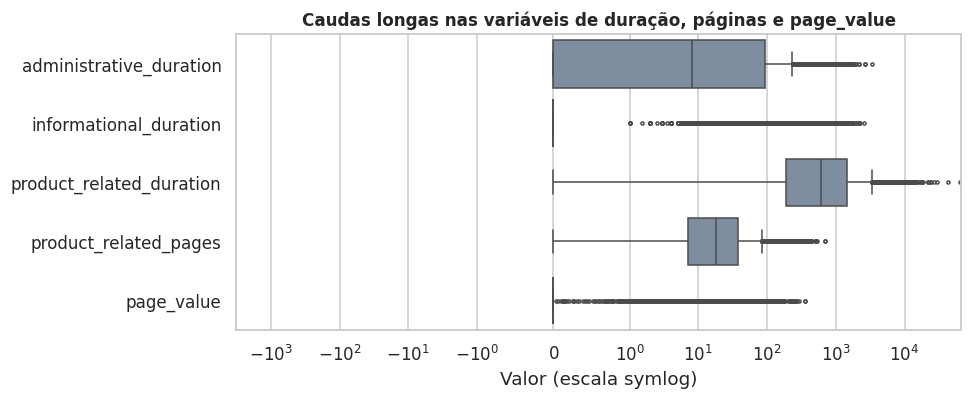

In [36]:
cols_out = ["administrative_duration", "informational_duration", "product_related_duration",
            "product_related_pages", "page_value"]


def resumo_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return pd.Series({
        "% zeros": 100 * (s == 0).mean(),
        "mediana": s.median(),
        "p99": s.quantile(0.99),
        "máximo": s.max(),
        "% acima de Q3+1,5·IQR": 100 * (s > q3 + 1.5 * (q3 - q1)).mean(),
    })


print(treino[cols_out].apply(resumo_outliers).T.round(1).to_string())
print(f"\nMaior tempo em páginas de produto: {treino['product_related_duration'].max() / 3600:.1f} horas")

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(data=treino[cols_out], orient="h", ax=ax, color=COR_NAO, fliersize=2)
ax.set_xscale("symlog", linthresh=1)
ax.set_xlabel("Valor (escala symlog)")
ax.set_title("Caudas longas nas variáveis de duração, páginas e page_value")
plt.tight_layout()
plt.show()

**Decisão: manter os outliers, sem remover nem cortar (winsorizar).** Justificativas:

1. **Não parecem erros de medição.** Não há valores negativos nem durações incoerentes com o número de páginas.
   Sessões longas e com muitas páginas são comportamento real de navegação (e, em geral, as mais ligadas à compra).
2. **A regra do IQR não é adequada aqui.** Em variáveis com muitos zeros (como `page_value`, em que Q3 = 0), o IQR é
   zero e qualquer valor positivo seria marcado como outlier. Marcaria justamente quem está navegando.
3. **Há alguns valores extremos suspeitos** (por exemplo, uma sessão de quase 18 horas em páginas de produto, possivelmente
   uma aba esquecida aberta ou tráfego automatizado), mas são raros e não dá para confirmar. Removê-los sem evidência
   seria uma decisão arbitrária.
4. **Tratamento na modelagem:** para o modelo linear, aplicamos `log1p` + padronização, o que comprime a cauda. Os modelos
   de árvore são insensíveis a escala e a valores extremos, então recebem os dados sem transformação numérica.

## 2. Análise exploratória

A EDA usa **somente o conjunto de treino limpo**, para não deixar o teste influenciar nenhuma decisão.
Cada pergunta traz a análise, o gráfico (com a justificativa do tipo escolhido em uma frase) e a interpretação.

In [37]:
eda = treino.copy()
eda["compra"] = eda["purchase"].map({0: "Não comprou", 1: "Comprou"})
ORD = ["Não comprou", "Comprou"]
MESES_PT = {"jan": "jan", "feb": "fev", "mar": "mar", "apr": "abr", "may": "mai", "jun": "jun",
            "jul": "jul", "aug": "ago", "sep": "set", "oct": "out", "nov": "nov", "dec": "dez"}


def fmt_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}".replace(".", ",")


def conversao_por(col, ordem=None):
    """Taxa de conversão, nº de sessões e intervalo de confiança aproximado (95%) por grupo."""
    t = eda.groupby(col, observed=True)["purchase"].agg(conv="mean", n="size")
    if ordem is not None:
        t = t.reindex(ordem)
    t["erro"] = 1.96 * np.sqrt(t["conv"] * (1 - t["conv"]) / t["n"])
    return t


def barras_conversao(ax, t, titulo, rotulos=None):
    nomes = rotulos if rotulos is not None else [str(i) for i in t.index]
    ax.bar(nomes, t["conv"], yerr=t["erro"], capsize=4, color=COR_NAO)
    ax.axhline(eda["purchase"].mean(), ls="--", color="black", lw=1)
    for i, (c, e, n) in enumerate(zip(t["conv"], t["erro"], t["n"])):
        ax.text(i, c + e + 0.004, f"{c:.1%}\nn={n}", ha="center", va="bottom", fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, (t["conv"] + t["erro"]).max() * 1.3)
    ax.set_ylabel("Taxa de compra")
    ax.set_title(titulo)

### Pergunta 1. Qual é a proporção de sessões que terminam em compra?

*Gráfico de barras: compara categorias discretas (duas classes) e mostra o desbalanceamento diretamente.*

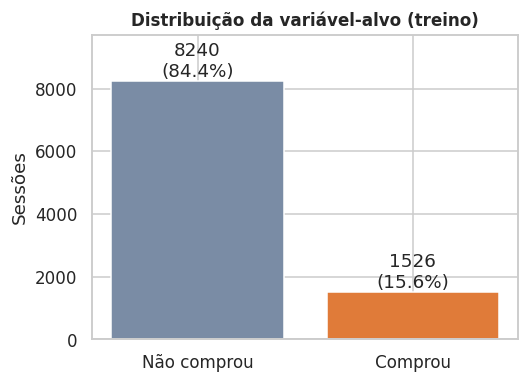

In [38]:
cont = eda["compra"].value_counts().reindex(ORD)

fig, ax = plt.subplots(figsize=(5, 3.6))
barras = ax.bar(cont.index, cont.values, color=[COR_NAO, COR_SIM])
for b, v in zip(barras, cont.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v / len(eda):.1%})", ha="center", va="bottom")
ax.set_ylim(0, cont.max() * 1.18)
ax.set_ylabel("Sessões")
ax.set_title("Distribuição da variável-alvo (treino)")
plt.show()

**Resposta.** Apenas **15,6%** das sessões terminam em compra (1.526 de 9.766). Um classificador que sempre responde
"não compra" teria **84,4% de acurácia** sem aprender nada. Por isso a acurácia não serve como métrica
principal, e o desbalanceamento precisa ser tratado na modelagem.

### Pergunta 2. A taxa de compra muda ao longo do ano?

*Gráfico de linha sobre barras: o mês é uma sequência temporal, então a linha mostra a tendência da taxa de compra, e as
barras mostram o volume de sessões que sustenta cada ponto.*

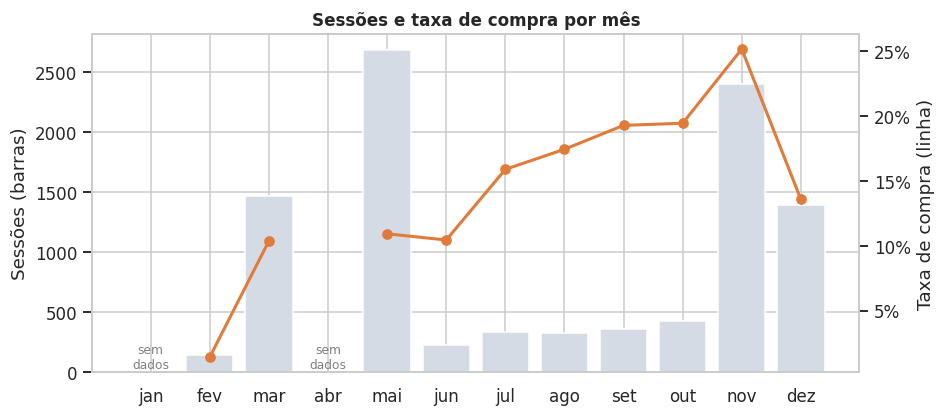

month     jan    feb     mar  apr     may    jun    jul    aug    sep    oct     nov     dec
% compra  NaN    1.4    10.4  NaN    10.9   10.4   15.9   17.4   19.3   19.4    25.2    13.6
sessões   0.0  142.0  1468.0  0.0  2684.0  230.0  340.0  327.0  358.0  427.0  2397.0  1393.0


In [39]:
mes = eda.groupby("month", observed=False)["purchase"].agg(conv="mean", n="size")   # inclui meses sem dados
x = [MESES_PT[m] for m in mes.index]

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(x, mes["n"], color="#D5DBE5")
ax1.set_ylabel("Sessões (barras)")
ax2 = ax1.twinx()
ax2.plot(x, mes["conv"], marker="o", color=COR_SIM, lw=2)
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_ylabel("Taxa de compra (linha)")
ax2.grid(False)
for m in mes.index[mes["n"] == 0]:
    ax1.text(MESES_PT[m], 40, "sem\ndados", ha="center", fontsize=8, color="gray")
ax1.set_title("Sessões e taxa de compra por mês")
plt.show()

print(mes.assign(conv=(100 * mes["conv"]).round(1)).rename(columns={"conv": "% compra", "n": "sessões"}).T.to_string())

**Resposta.** Há forte sazonalidade. A taxa de compra vai de **1,4% em fevereiro** a **25,2% em novembro**
(10,4% em março e 10,9% em maio, 13,6% em dezembro). Março, maio, novembro e dezembro concentram mais de 80% das sessões.
**Janeiro e abril não aparecem na base**, então o comportamento sazonal só é observado em 10 dos 12 meses.

### Pergunta 3. Visitantes novos compram mais do que os recorrentes?

*Gráfico de barras com intervalo de confiança: compara a taxa de compra entre poucos grupos e mostra a incerteza de cada um.*

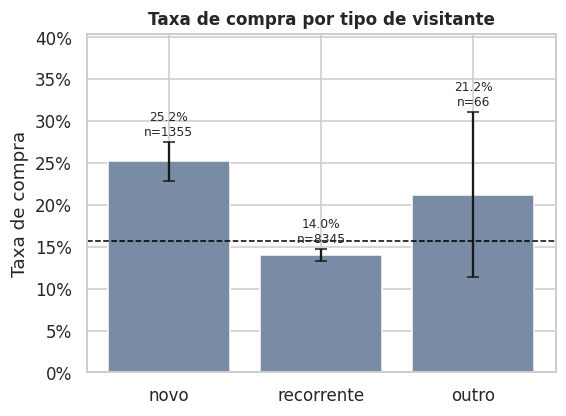

Teste qui-quadrado (tipo de visitante x compra): p < 0,001
Participação na base: {'returning': 85.4, 'new': 13.9, 'other': 0.7}


In [40]:
t = conversao_por("visitor_type", ["new", "returning", "other"])
fig, ax = plt.subplots(figsize=(5.5, 4))
barras_conversao(ax, t, "Taxa de compra por tipo de visitante", ["novo", "recorrente", "outro"])
plt.show()

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(eda["visitor_type"], eda["purchase"]))
print(f"Teste qui-quadrado (tipo de visitante x compra): {fmt_p(p)}")
print(f"Participação na base: {(eda['visitor_type'].value_counts(normalize=True) * 100).round(1).to_dict()}")

**Resposta.** Sim. **Visitantes novos compram 25,2%** das vezes contra **14,0% dos recorrentes**, diferença
estatisticamente significativa (qui-quadrado, p < 0,001). O grupo `other` (21,2%) tem apenas 66 sessões, então
sua estimativa é imprecisa (intervalo largo). Os recorrentes são a maioria absoluta das sessões (85%).

### Pergunta 4. Sessões em fim de semana convertem mais?

*Gráfico de barras com intervalo de confiança, pelo mesmo motivo da pergunta anterior.*

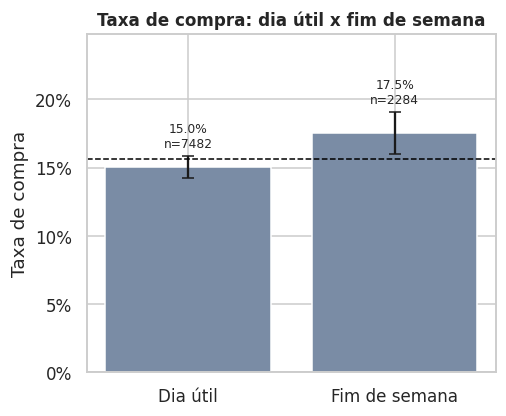

Teste qui-quadrado (fim de semana x compra): p = 0,005


In [41]:
eda["periodo"] = eda["weekend"].map({0: "Dia útil", 1: "Fim de semana"})
t = conversao_por("periodo", ["Dia útil", "Fim de semana"])
fig, ax = plt.subplots(figsize=(4.8, 4))
barras_conversao(ax, t, "Taxa de compra: dia útil x fim de semana")
plt.show()

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(eda["weekend"], eda["purchase"]))
print(f"Teste qui-quadrado (fim de semana x compra): {fmt_p(p)}")

**Resposta.** Pouco. Fim de semana tem **17,5%** de compra contra **15,0%** em dias úteis. A diferença (2,5 pontos
percentuais) é estatisticamente significativa (p ≈ 0,005), mas de **efeito pequeno** quando comparada às demais
variáveis. Não deve ser um preditor importante.

### Pergunta 5. O `page_value` é diferente entre quem compra e quem não compra?

*Boxplot (escala symlog) para comparar a distribuição entre dois grupos com cauda longa, mais barras para a parcela de
sessões com `page_value` positivo.*

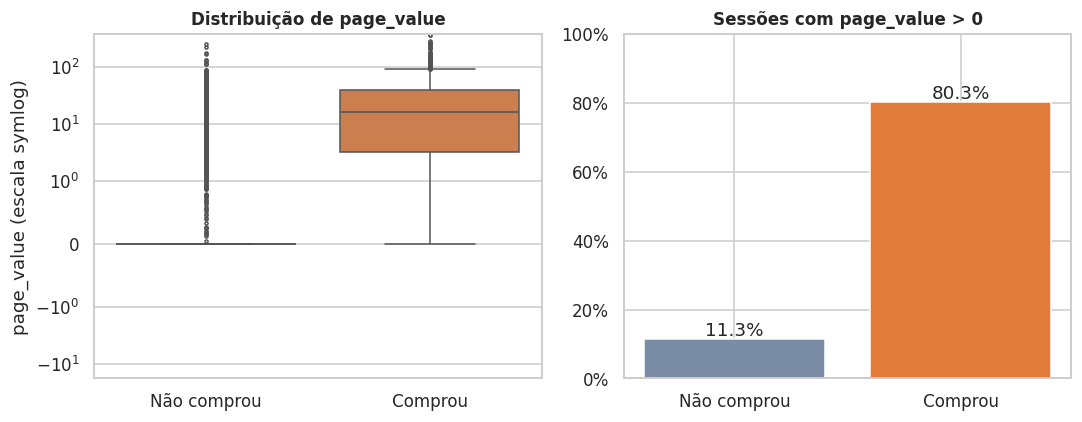

Mann-Whitney U (page_value x compra): p < 0,001
Taxa de compra quando page_value = 0 : 4.0%
Taxa de compra quando page_value > 0 : 56.7%
Média de page_value: {'Comprou': 27.3, 'Não comprou': 1.9}


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.boxplot(data=eda, x="compra", y="page_value", order=ORD, hue="compra", hue_order=ORD,
            palette=PALETA, legend=False, ax=axes[0], fliersize=2)
axes[0].set_yscale("symlog", linthresh=1)
axes[0].set_xlabel("")
axes[0].set_ylabel("page_value (escala symlog)")
axes[0].set_title("Distribuição de page_value")

pos = eda.groupby("compra")["page_value"].apply(lambda s: (s > 0).mean()).reindex(ORD)
axes[1].bar(pos.index, pos.values, color=[COR_NAO, COR_SIM])
for i, v in enumerate(pos.values):
    axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].set_ylim(0, 1)
axes[1].set_title("Sessões com page_value > 0")
plt.tight_layout()
plt.show()

u, p = stats.mannwhitneyu(eda.loc[eda.purchase == 1, "page_value"], eda.loc[eda.purchase == 0, "page_value"])
print(f"Mann-Whitney U (page_value x compra): {fmt_p(p)}")
print("Taxa de compra quando page_value = 0 :", f"{eda.loc[eda.page_value == 0, 'purchase'].mean():.1%}")
print("Taxa de compra quando page_value > 0 :", f"{eda.loc[eda.page_value > 0, 'purchase'].mean():.1%}")
print("Média de page_value:", eda.groupby("compra")["page_value"].mean().round(1).to_dict())

**Resposta.** Muito diferente. **80,3% dos compradores** têm `page_value > 0`, contra **11,3%** dos não compradores.
A taxa de compra é de apenas **4,0%** quando `page_value = 0` e sobe para **56,7%** quando `page_value > 0`
(Mann-Whitney, p < 0,001). Essa associação é tão forte que levanta a suspeita de **vazamento de dados**: `page_value` é
calculado a partir de páginas que levaram a transações. Isso será tratado explicitamente na modelagem.

### Pergunta 6. Compradores navegam mais, e por mais tempo, em páginas de produto?

*Boxplots lado a lado (escala symlog), pois comparam distribuições assimétricas com zeros entre os dois grupos.*

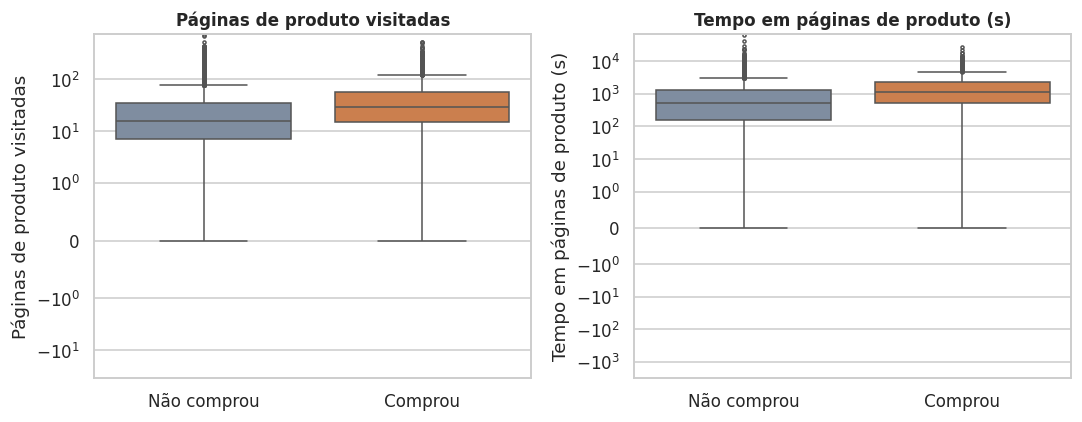

compra                    Comprou  Não comprou
product_related_pages        29.0         16.0
product_related_duration   1110.7        520.1

Correlação de Spearman entre páginas e tempo em produtos: 0.88


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, rot in zip(axes, ["product_related_pages", "product_related_duration"],
                        ["Páginas de produto visitadas", "Tempo em páginas de produto (s)"]):
    sns.boxplot(data=eda, x="compra", y=col, order=ORD, hue="compra", hue_order=ORD,
                palette=PALETA, legend=False, ax=ax, fliersize=2)
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xlabel("")
    ax.set_ylabel(rot)
    ax.set_title(rot)
plt.tight_layout()
plt.show()

print(eda.groupby("compra")[["product_related_pages", "product_related_duration"]].median().round(1).T.to_string())
rho = eda[["product_related_pages", "product_related_duration"]].corr("spearman").iloc[0, 1]
print(f"\nCorrelação de Spearman entre páginas e tempo em produtos: {rho:.2f}")

**Resposta.** Sim. A mediana é de **29 páginas** de produto entre compradores contra **16** entre não compradores, e o
tempo mediano é de **1.111 s (~18,5 min)** contra **520 s (~8,7 min)**. Páginas e tempo são fortemente correlacionados
entre si (Spearman 0,88), o que indica **redundância** entre as duas variáveis (relevante para modelos lineares).

### Pergunta 7. Taxas de rejeição e de saída mais baixas estão associadas à compra?

*Histogramas sobrepostos (densidade): mostram a forma da distribuição de uma variável contínua em cada classe, mesmo com
tamanhos de grupo muito diferentes.*

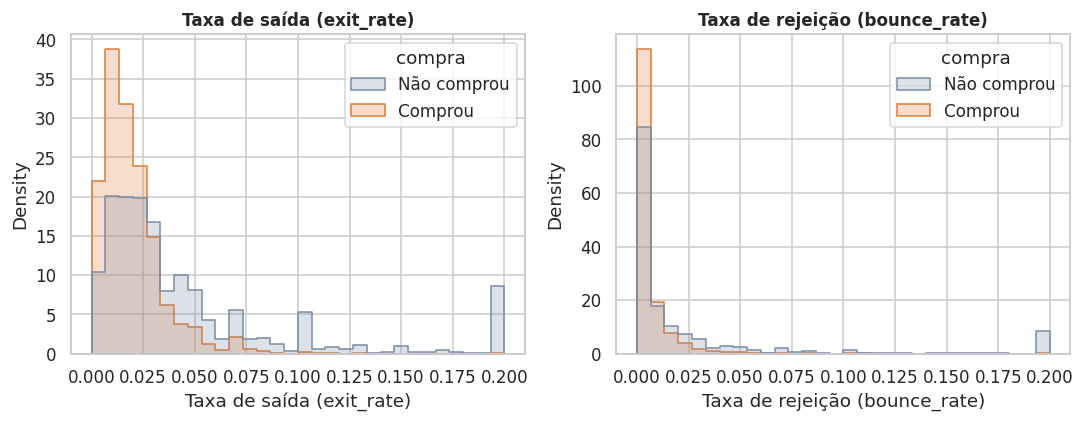

            exit_rate        bounce_rate       
               median   mean      median   mean
compra                                         
Comprou         0.016  0.020       0.000  0.005
Não comprou     0.029  0.046       0.004  0.023


In [44]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, nome in zip(axes, ["exit_rate", "bounce_rate"], ["Taxa de saída (exit_rate)", "Taxa de rejeição (bounce_rate)"]):
    sns.histplot(data=eda, x=col, hue="compra", hue_order=ORD, palette=PALETA, stat="density",
                 common_norm=False, bins=30, element="step", ax=ax)
    ax.set_xlabel(nome)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

print(eda.groupby("compra")[["exit_rate", "bounce_rate"]].agg(["median", "mean"]).round(3).to_string())

**Resposta.** Sim. A taxa de saída mediana é de **0,016** entre compradores e **0,029** entre não compradores. A taxa de
rejeição é praticamente **zero** entre compradores (mediana 0,000; média 0,005) contra média de 0,023 entre não compradores.
Sessões em páginas com saída e rejeição historicamente baixas tendem a terminar em compra.

### Pergunta 8. A proximidade de uma data comercial especial aumenta a compra?

*Gráfico de barras com intervalo de confiança: `special_day` assume poucos valores, então agrupamos em faixas e comparamos categorias.*

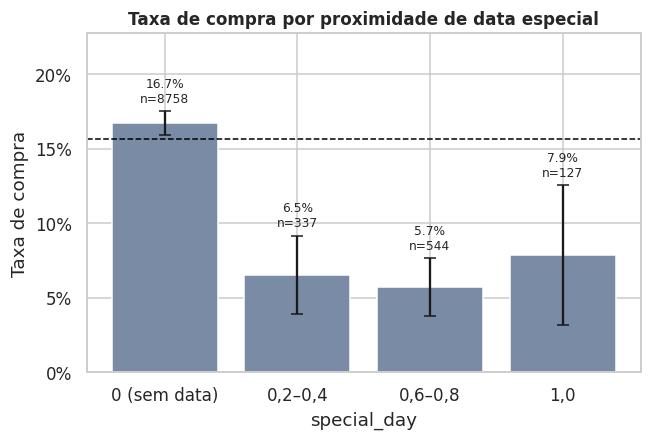

Meses com special_day > 0 (% das sessões do mês):
{'feb': 43.0, 'may': 35.3}

Só em maio, taxa de compra com special_day = 0 : 13.3%
Só em maio, taxa de compra com special_day > 0 : 6.5%


In [45]:
eda["faixa_special"] = pd.cut(eda["special_day"], [-0.01, 0, 0.4, 0.8, 1.0],
                              labels=["0 (sem data)", "0,2–0,4", "0,6–0,8", "1,0"])
t = conversao_por("faixa_special")
fig, ax = plt.subplots(figsize=(6.5, 4))
barras_conversao(ax, t, "Taxa de compra por proximidade de data especial")
ax.set_xlabel("special_day")
plt.show()

print("Meses com special_day > 0 (% das sessões do mês):")
print((eda.assign(sp=eda.special_day > 0).groupby("month", observed=True)["sp"].mean()
       .loc[lambda s: s > 0] * 100).round(1).to_dict())
mai = eda[eda.month == "may"]
print("\nSó em maio, taxa de compra com special_day = 0 :", f"{mai.loc[mai.special_day == 0, 'purchase'].mean():.1%}")
print("Só em maio, taxa de compra com special_day > 0 :", f"{mai.loc[mai.special_day > 0, 'purchase'].mean():.1%}")

**Resposta.** Ao contrário do que se esperaria, **não**. Sessões próximas de datas especiais convertem **menos**
(**6,2%** contra **16,7%** nas demais). Atenção: `special_day > 0` só ocorre em **fevereiro** e **maio**, então a variável
está misturada com o mês. Mesmo dentro de maio, a taxa é menor perto da data (6,5% contra 13,3%), então o efeito não
é só sazonalidade. Uma hipótese é que a data atraia mais visitas de navegação do que de compra, mas a base não permite
confirmar isso.

### Pergunta 9. Visitar páginas administrativas e informativas aumenta a chance de compra?

*Barras com intervalo de confiança: as contagens de páginas foram agrupadas em faixas para comparar a taxa de compra entre categorias.*

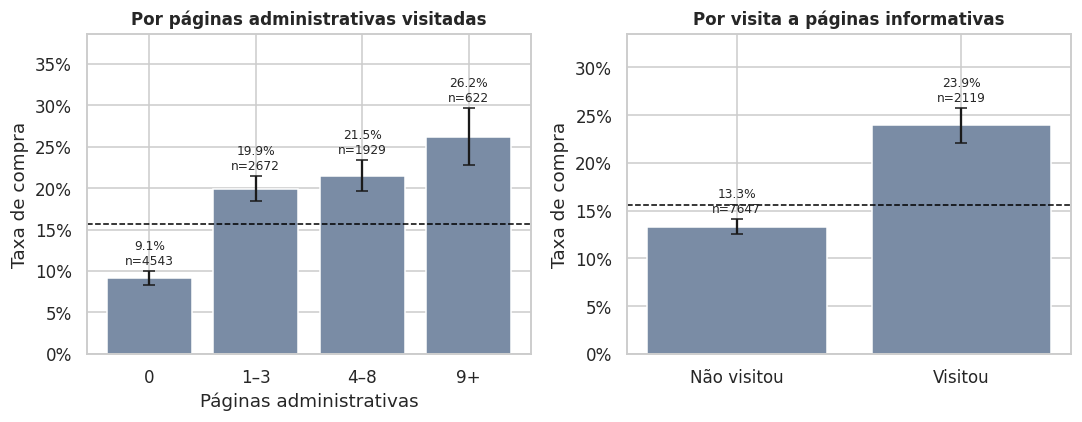

In [46]:
eda["faixa_adm"] = pd.cut(eda["administrative_pages"], [-1, 0, 3, 8, 1000], labels=["0", "1–3", "4–8", "9+"])
eda["visitou_info"] = np.where(eda["informational_pages"] > 0, "Visitou", "Não visitou")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
barras_conversao(axes[0], conversao_por("faixa_adm"), "Por páginas administrativas visitadas")
axes[0].set_xlabel("Páginas administrativas")
barras_conversao(axes[1], conversao_por("visitou_info", ["Não visitou", "Visitou"]), "Por visita a páginas informativas")
plt.tight_layout()
plt.show()

**Resposta.** Sim, de forma gradual. Sem nenhuma página administrativa, a taxa de compra é de **9,1%**. Ela sobe para **19,9%**
(1–3 páginas), **21,5%** (4–8) e **26,2%** (9 ou mais). Quem visitou alguma página informativa compra **23,9%** das
vezes, contra **13,3%** de quem não visitou. Esses acessos podem indicar um interesse mais sério, como consultar
informações da conta, entrega ou trocas antes de comprar.

### Pergunta 10. A origem do tráfego e a região influenciam a taxa de compra?

*Barras horizontais ordenadas: há muitas categorias, e a ordenação e os rótulos longos ficam mais legíveis na horizontal.*

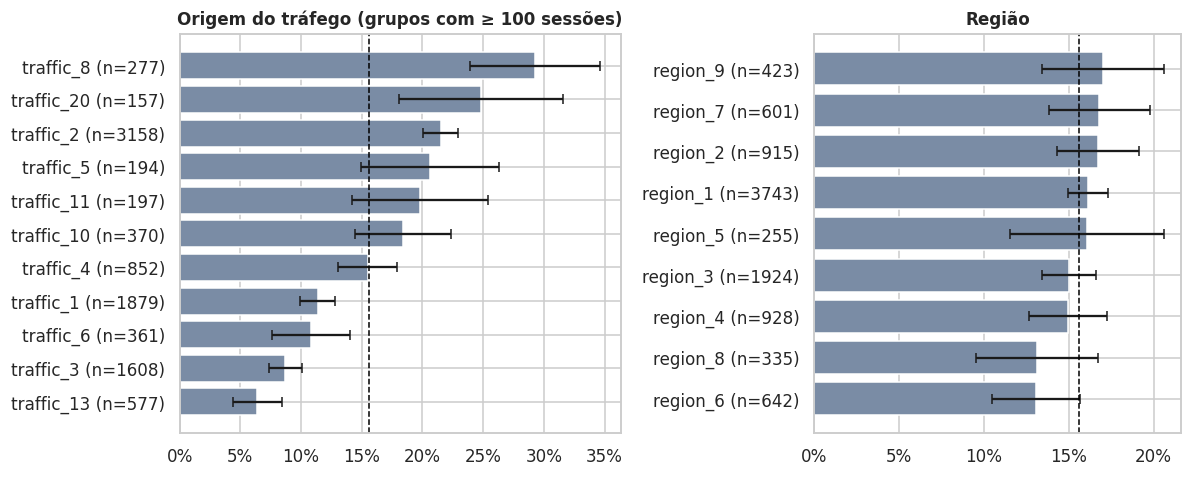

Amplitude da taxa de compra - origem do tráfego: 6.4% a 29.2%
Amplitude da taxa de compra - região:            13.1% a 17.0%


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

t = conversao_por("traffic_type")
t = t[t["n"] >= 100].sort_values("conv")
axes[0].barh([f"{i} (n={n})" for i, n in zip(t.index, t["n"])], t["conv"], xerr=t["erro"], capsize=3, color=COR_NAO)
axes[0].axvline(eda["purchase"].mean(), ls="--", color="black", lw=1)
axes[0].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_title("Origem do tráfego (grupos com ≥ 100 sessões)")

r = conversao_por("region").sort_values("conv")
axes[1].barh([f"{i} (n={n})" for i, n in zip(r.index, r["n"])], r["conv"], xerr=r["erro"], capsize=3, color=COR_NAO)
axes[1].axvline(eda["purchase"].mean(), ls="--", color="black", lw=1)
axes[1].xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[1].set_title("Região")
plt.tight_layout()
plt.show()

print("Amplitude da taxa de compra - origem do tráfego:", f"{t['conv'].min():.1%} a {t['conv'].max():.1%}")
print("Amplitude da taxa de compra - região:           ", f"{r['conv'].min():.1%} a {r['conv'].max():.1%}")

**Resposta.** A **origem do tráfego importa bastante**: entre os grupos com pelo menos 100 sessões, a taxa varia de **6,4%**
(`traffic_13`) a **29,2%** (`traffic_8`), e `traffic_2`, o maior grupo, converte 21,5%. Já a **região** quase não discrimina
(de 13,1% a 17,0%, com intervalos que se sobrepõem). Como os códigos são anonimizados, não dá para saber quais canais
são esses.

### Pergunta 11. Quais variáveis numéricas mais se relacionam com a compra e entre si?

*Mapa de calor da correlação de Spearman: resume muitas relações par a par de uma vez. Usamos Spearman por ser robusto
às caudas longas e às relações não lineares monótonas.*

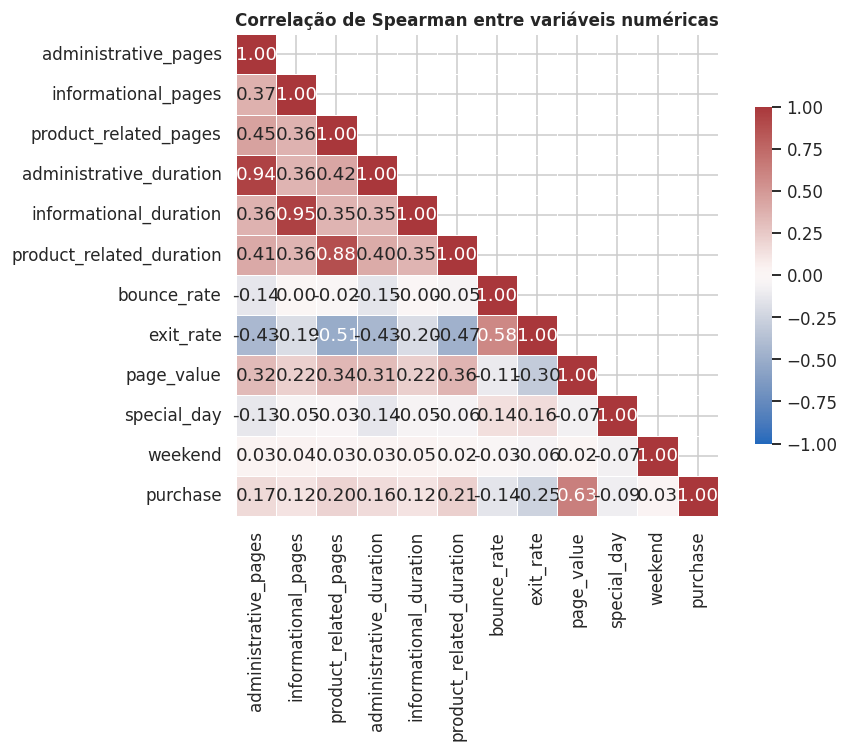

Correlação com o alvo (purchase):
page_value                  0.63
exit_rate                  -0.25
product_related_duration    0.21
product_related_pages       0.20
administrative_pages        0.17
administrative_duration     0.16
bounce_rate                -0.14
informational_duration      0.12
informational_pages         0.12
special_day                -0.09
weekend                     0.03


In [48]:
cols_cor = NUMERICAS_INT + NUMERICAS_FLOAT + ["weekend", "purchase"]
cor = eda[cols_cor].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cor, mask=np.triu(np.ones_like(cor, dtype=bool), k=1), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlação de Spearman entre variáveis numéricas")
plt.tight_layout()
plt.show()

print("Correlação com o alvo (purchase):")
print(cor["purchase"].drop("purchase").sort_values(key=abs, ascending=False).round(2).to_string())

**Resposta.** `page_value` é, de longe, a variável mais associada à compra (Spearman **0,63**). Em seguida vêm
`exit_rate` (−0,25), `product_related_duration` (0,21), `product_related_pages` (0,20), as variáveis administrativas
(0,16–0,17) e `bounce_rate` (−0,14). Entre as variáveis explicativas há **colinearidade**: páginas e tempo em produtos
(0,88), `bounce_rate` e `exit_rate` (0,58), `exit_rate` e páginas de produto (−0,51).

### Síntese dos achados e limitações da base

**Achados principais**

- Só **15,6%** das sessões compram: a base é desbalanceada e a acurácia não é uma métrica adequada.
- O **momento** importa muito (de 1,4% em fevereiro a 25,2% em novembro), e a **origem do tráfego** também (6,4% a 29,2%).
- **Visitantes novos** convertem mais que recorrentes (25,2% vs. 14,0%). Fim de semana tem efeito pequeno.
- **Engajamento** (páginas de produto, tempo, páginas administrativas e informativas) e **saída/rejeição baixas**
  acompanham a compra.
- `page_value` é a variável mais associada ao alvo por larga margem, o que exige cuidado com **vazamento**.

**Limitações**

- Os dados vêm de **uma única loja** e cerca de **um ano**, sem janeiro e abril. A sazonalidade não é generalizável.
- Cada linha é uma **sessão**, não um cliente. Visitantes recorrentes podem aparecer várias vezes, o que viola a
  independência das observações.
- `operating_system`, `browser`, `region` e `traffic_type` são **códigos anonimizados**, sem como interpretar o significado.
- `special_day` está misturada com o mês (só é positiva em fevereiro e maio).
- As associações são **observacionais**: não indicam causa.
- A remoção de duplicatas (98 sessões `no`) pode ter retirado sessões reais idênticas, e isso aumenta ligeiramente a
  proporção de compras do treino (de 15,5% para 15,6%).

## 3. Modelagem

### 3.1 Tarefa preditiva e variável-alvo

- **Tarefa:** classificação binária supervisionada.
- **Alvo:** `purchase` (1 = a sessão terminou em compra).
- **Instante da previsão:** consideramos que a previsão é feita **durante/ao final da navegação**, usando os agregados
  da sessão (páginas, tempos, taxas). Um uso realista seria disparar uma ação (por exemplo, um cupom) para sessões com
  alta probabilidade de compra ou de abandono.

### 3.2 Risco de vazamento de dados: o caso do `page_value`

O `page_value` é o valor médio das páginas visitadas **antes de transações**. Por construção, ele é calculado
a partir de sessões que terminaram em compra, e a própria sessão que queremos prever pode contribuir para esse valor.
Na EDA ele aparece com associação muito acima das demais variáveis (Spearman 0,63).

Como não dá para ter certeza de que essa informação estaria disponível **antes** do desfecho em uma aplicação real,
treinamos e avaliamos **dois cenários**, mostrados lado a lado:

| Cenário | Atributos | Leitura |
| --- | --- | --- |
| **A, com `page_value`** | todos os 17 | Desempenho "ótimo", mas potencialmente inflado por vazamento. |
| **B, sem `page_value`** | 16 (sem `page_value`) | Estimativa mais conservadora e realista do que se consegue prever só com navegação, origem e período. |

### 3.3 Separação treino/teste e cuidados contra vazamento

- A separação **já vem pronta** do professor (treino e teste) e é **preservada**. O teste só é usado **uma vez**, no fim.
- Todas as escolhas (modelo, hiperparâmetros, limiar de decisão) são feitas **apenas com validação cruzada no treino**.
- As transformações que aprendem algo dos dados (`log1p` + padronização e *one-hot encoding*) ficam **dentro de um
  `Pipeline`**, ajustadas dentro de cada dobra da validação cruzada, sem enxergar a dobra de validação.
- Não usamos reamostragem (SMOTE ou *undersampling*): o balanceamento é feito por **pesos de classe**
  (`class_weight`), que não criam nem removem linhas e, portanto, não contaminam a validação.
- O limiar de decisão é escolhido com predições **fora da dobra** (*out-of-fold*) no treino, nunca no teste.
- A importância das variáveis (final) é calculada no teste apenas para **interpretação**, sem alterar nenhuma escolha.

### 3.4 Transformações, validação e métricas

**Transformações (dentro do `Pipeline`)**

| Tipo | Regressão logística | Random Forest / HistGradientBoosting |
| --- | --- | --- |
| Numéricas | `log1p` + `StandardScaler` (reduz caudas, equaliza escalas) | sem transformação (árvores não dependem de escala) |
| Categóricas | *one-hot*; categorias com menos de 20 sessões são agrupadas em "infrequente" | igual |
| Seleção de atributos | não aplicada. A regularização L2 e as árvores já lidam com variáveis redundantes | igual |
| Balanceamento | `class_weight="balanced"` | `class_weight="balanced"` / `"balanced_subsample"` |

**Validação:** `StratifiedKFold` com 5 dobras (embaralhado, `random_state=42`), que mantém a proporção de compras em cada dobra.

**Métricas** (escolha justificada pelo desbalanceamento de 15,6%)

- **PR-AUC (*average precision*): métrica principal.** Foca na classe minoritária e não é inflada pelos muitos negativos.
  Também é a métrica usada na busca de hiperparâmetros.
- **ROC-AUC:** qualidade do ranqueamento, independente de limiar.
- **Precisão, revocação (*recall*) e F1** da classe "compra": mostram o compromisso entre acertar quem compra e não alarmar à toa.
- **Acurácia balanceada:** média da revocação das duas classes.
- **Acurácia simples não é usada**: um modelo trivial já teria 84,4%.

### 3.5 Técnicas comparadas

| Técnica | Papel |
| --- | --- |
| `DummyClassifier` (prevalência) | Referência trivial: o piso que qualquer modelo precisa superar. |
| **Regressão Logística** | **Baseline** simples e interpretável, com hiperparâmetros padrão. |
| **Random Forest** | Conjunto de árvores (*bagging*), captura interações e não linearidades. Com busca de hiperparâmetros. |
| **HistGradientBoosting** | *Boosting* de árvores, geralmente o mais forte em dados tabulares. Com busca de hiperparâmetros. |

In [49]:
COL_NUM = NUMERICAS_INT + NUMERICAS_FLOAT + ["weekend"]
COL_CAT = CATEGORICAS

X_train = treino.drop(columns="purchase").copy()
y_train = treino["purchase"]
X_test = teste.drop(columns="purchase").copy()
y_test = teste["purchase"]
for c in COL_CAT:                       # strings simples para o OneHotEncoder
    X_train[c] = X_train[c].astype(str)
    X_test[c] = X_test[c].astype(str)

CENARIOS = {
    "A (com page_value)": COL_NUM + COL_CAT,
    "B (sem page_value)": [c for c in COL_NUM if c != "page_value"] + COL_CAT,
}


def montar_pipeline(modelo, colunas, escalar):
    num = [c for c in colunas if c in COL_NUM]
    cat = [c for c in colunas if c in COL_CAT]
    if escalar:
        tr_num = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                           ("esc", StandardScaler())])
    else:
        tr_num = "passthrough"
    prep = ColumnTransformer([
        ("num", tr_num, num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), cat),
    ])
    return Pipeline([("prep", prep), ("modelo", clone(modelo))])


MODELOS = {   # nome: (estimador, escalar?)
    "Dummy (prevalência)": (DummyClassifier(strategy="prior"), False),
    "Regressão Logística (baseline)": (LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED), True),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=SEED), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED), False),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "bal_acc": "balanced_accuracy",
}
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Cenário A:", len(CENARIOS["A (com page_value)"]), "atributos | Cenário B:", len(CENARIOS["B (sem page_value)"]), "atributos")

Treino: (9766, 17) | Teste: (2466, 17)
Cenário A: 17 atributos | Cenário B: 16 atributos


### 3.6 Validação cruzada dos modelos com hiperparâmetros iniciais (somente treino)

Primeira comparação, com limiar padrão (0,5). O teste ainda não foi tocado.

In [50]:
linhas = []
for cen, cols in CENARIOS.items():
    for nome, (modelo, escalar) in MODELOS.items():
        r = cross_validate(montar_pipeline(modelo, cols, escalar), X_train[cols], y_train, cv=cv, scoring=SCORING, n_jobs=1)
        linhas.append({"Cenário": cen, "Modelo": nome,
                       **{m: r[f"test_{m}"].mean() for m in SCORING},
                       "PR-AUC (desvio)": r["test_pr_auc"].std()})

cv_inicial = pd.DataFrame(linhas).set_index(["Cenário", "Modelo"]).round(3)
cv_inicial.columns = ["ROC-AUC", "PR-AUC", "Precisão", "Revocação", "F1", "Acur. balanceada", "PR-AUC (desvio)"]
cv_inicial

ROC-AUC  PR-AUC  Precisão  \
Cenário            Modelo                                                      
A (com page_value) Dummy (prevalência)               0.500   0.156     0.000   
                   Regressão Logística (baseline)    0.918   0.672     0.547   
                   Random Forest                     0.929   0.738     0.635   
                   HistGradientBoosting              0.928   0.743     0.590   
B (sem page_value) Dummy (prevalência)               0.500   0.156     0.000   
                   Regressão Logística (baseline)    0.751   0.329     0.272   
                   Random Forest                     0.781   0.385     0.420   
                   HistGradientBoosting              0.769   0.362     0.313   

                                                   Revocação     F1  \
Cenário            Modelo                                             
A (com page_value) Dummy (prevalência)                 0.000  0.000   
                   Regressão Logística (baseline)      0.801  0.650   
                   Random Forest                       0.722  0.676   
                   HistGradientBoosting                0.782  0.673   
B (sem page_value) Dummy (prevalência)                 0.000  0.000   
                   Regressão Logística (baseline)      0.744  0.398   
                   Random Forest                       0.353  0.383   
                   HistGradientBoosting                0.618  0.415   

                                                   Acur. balanceada  \
Cenário            Modelo                                             
A (com page_value) Dummy (prevalência)                        0.500   
                   Regressão Logística (baseline)             0.839   
                   Random Forest                              0.822   
                   HistGradientBoosting                       0.841   
B (sem page_value) Dummy (prevalência)                        0.500   
                   Regressão Logística (baseline)             0.687   
                   Random Forest                              0.631   
                   HistGradientBoosting                       0.683   

                                                   PR-AUC (desvio)  
Cenário            Modelo                                           
A (com page_value) Dummy (prevalência)                       0.000  
                   Regressão Logística (baseline)            0.040  
                   Random Forest                             0.039  
                   HistGradientBoosting                      0.039  
B (sem page_value) Dummy (prevalência)                       0.000  
                   Regressão Logística (baseline)            0.009  
                   Random Forest                             0.021  
                   HistGradientBoosting                      0.020

### 3.7 Busca de hiperparâmetros (Random Forest e HistGradientBoosting)

**Abordagem:** `RandomizedSearchCV`, que sorteia combinações do espaço de busca em vez de testar todas, mais barato e
em geral quase tão bom quanto a busca em grade. Usa as **mesmas 5 dobras estratificadas do treino**, com
`average_precision` (PR-AUC) como critério, e reajusta o melhor modelo no treino completo. A busca é feita separadamente
em cada cenário. A regressão logística permanece como baseline, com hiperparâmetros padrão.

In [51]:
ESPACOS = {
    "Random Forest": ({
        "modelo__n_estimators": [200, 300, 500],
        "modelo__max_depth": [None, 6, 10, 16],
        "modelo__min_samples_leaf": [1, 3, 5, 10],
        "modelo__max_features": ["sqrt", 0.3, 0.5],
    }, 12),
    "HistGradientBoosting": ({
        "modelo__learning_rate": [0.03, 0.05, 0.1],
        "modelo__max_leaf_nodes": [8, 15, 31],
        "modelo__min_samples_leaf": [20, 50, 100],
        "modelo__l2_regularization": [0, 0.1, 1, 10],
        "modelo__max_iter": [100, 200, 300],
    }, 15),
}

melhores = {}      # (cenário, modelo) -> pipeline ajustado no treino completo
resumo_busca = []
for cen, cols in CENARIOS.items():
    for nome, (espaco, n_iter) in ESPACOS.items():
        modelo, escalar = MODELOS[nome]
        busca = RandomizedSearchCV(montar_pipeline(modelo, cols, escalar), espaco, n_iter=n_iter, cv=cv,
                                   scoring="average_precision", random_state=SEED, n_jobs=1, refit=True)
        busca.fit(X_train[cols], y_train)
        melhores[(cen, nome)] = busca.best_estimator_
        params = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
        resumo_busca.append({"Cenário": cen, "Modelo": nome, "PR-AUC (CV)": round(busca.best_score_, 3), "Melhores hiperparâmetros": params})

pd.DataFrame(resumo_busca).set_index(["Cenário", "Modelo"])

PR-AUC (CV)  \
Cenário            Modelo                              
A (com page_value) Random Forest               0.751   
                   HistGradientBoosting        0.754   
B (sem page_value) Random Forest               0.384   
                   HistGradientBoosting        0.377   

                                                                  Melhores hiperparâmetros  
Cenário            Modelo                                                                   
A (com page_value) Random Forest         {'n_estimators': 300, 'min_samples_leaf': 5, '...  
                   HistGradientBoosting  {'min_samples_leaf': 50, 'max_leaf_nodes': 31,...  
B (sem page_value) Random Forest         {'n_estimators': 200, 'min_samples_leaf': 5, '...  
                   HistGradientBoosting  {'min_samples_leaf': 100, 'max_leaf_nodes': 15...

### 3.8 Escolha do limiar de decisão (somente treino)

Com 15,6% de positivos, o limiar 0,5 raramente é o melhor. Escolhemos, para cada modelo, o limiar que **maximiza o F1** da
classe "compra" usando probabilidades **fora da dobra** (*out-of-fold*) do treino. Assim o limiar é decidido sem olhar o
teste. O F1 é uma escolha de equilíbrio entre precisão e revocação; em uma aplicação real, o limiar deveria refletir
o custo de errar em cada sentido (por exemplo, o custo de um cupom desperdiçado frente à venda perdida).

In [52]:
def pipeline_final(cen, nome):
    """Modelo com hiperparâmetros finais (ainda não ajustado). Dummy e regressão logística usam a configuração base."""
    if (cen, nome) in melhores:
        return clone(melhores[(cen, nome)])
    modelo, escalar = MODELOS[nome]
    return montar_pipeline(modelo, CENARIOS[cen], escalar)


def melhor_limiar(y, p):
    prec, rec, lim = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    return float(lim[np.argmax(f1)])


limiares = {}
for cen, cols in CENARIOS.items():
    for nome in MODELOS:
        p_oof = cross_val_predict(pipeline_final(cen, nome), X_train[cols], y_train, cv=cv, method="predict_proba")[:, 1]
        limiares[(cen, nome)] = melhor_limiar(y_train, p_oof)

pd.Series({f"{c} | {m}": round(v, 3) for (c, m), v in limiares.items()}, name="limiar (maximiza F1 no treino)").to_frame()

,limiar (maximiza F1 no treino)
A (com page_value) | Dummy (prevalência),0.156
A (com page_value) | Regressão Logística (baseline),0.610
A (com page_value) | Random Forest,0.483
A (com page_value) | HistGradientBoosting,0.682
B (sem page_value) | Dummy (prevalência),0.156
B (sem page_value) | Regressão Logística (baseline),0.541
B (sem page_value) | Random Forest,0.324
B (sem page_value) | HistGradientBoosting,0.560


## 4. Resultados

Agora, e só agora, os modelos são ajustados no **treino completo** e avaliados **uma única vez no teste**.

In [53]:
linhas, probas, modelos_finais = [], {}, {}
for cen, cols in CENARIOS.items():
    for nome in MODELOS:
        pipe = pipeline_final(cen, nome).fit(X_train[cols], y_train)
        p = pipe.predict_proba(X_test[cols])[:, 1]
        lim = limiares[(cen, nome)]
        pred = (p >= lim).astype(int)
        probas[(cen, nome)], modelos_finais[(cen, nome)] = p, pipe
        linhas.append({
            "Cenário": cen, "Modelo": nome,
            "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
            "Precisão": precision_score(y_test, pred, zero_division=0), "Revocação": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred), "Acur. balanceada": balanced_accuracy_score(y_test, pred),
            "Limiar": lim,
        })

resultados = pd.DataFrame(linhas).set_index(["Cenário", "Modelo"]).round(3)
print(f"Prevalência de compras no teste: {y_test.mean():.3f} (= PR-AUC esperado de um modelo sem poder preditivo)")
resultados

Prevalência de compras no teste: 0.155 (= PR-AUC esperado de um modelo sem poder preditivo)


ROC-AUC  PR-AUC  Precisão  \
Cenário            Modelo                                                      
A (com page_value) Dummy (prevalência)               0.500   0.155     0.155   
                   Regressão Logística (baseline)    0.924   0.656     0.588   
                   Random Forest                     0.936   0.759     0.601   
                   HistGradientBoosting              0.936   0.752     0.630   
B (sem page_value) Dummy (prevalência)               0.500   0.155     0.155   
                   Regressão Logística (baseline)    0.763   0.333     0.285   
                   Random Forest                     0.781   0.386     0.294   
                   HistGradientBoosting              0.785   0.369     0.305   

                                                   Revocação     F1  \
Cenário            Modelo                                             
A (com page_value) Dummy (prevalência)                 1.000  0.268   
                   Regressão Logística (baseline)      0.775  0.669   
                   Random Forest                       0.796  0.685   
                   HistGradientBoosting                0.775  0.695   
B (sem page_value) Dummy (prevalência)                 1.000  0.268   
                   Regressão Logística (baseline)      0.694  0.404   
                   Random Forest                       0.723  0.418   
                   HistGradientBoosting                0.644  0.414   

                                                   Acur. balanceada  Limiar  
Cenário            Modelo                                                    
A (com page_value) Dummy (prevalência)                        0.500   0.156  
                   Regressão Logística (baseline)             0.838   0.610  
                   Random Forest                              0.849   0.483  
                   HistGradientBoosting                       0.846   0.682  
B (sem page_value) Dummy (prevalência)                        0.500   0.156  
                   Regressão Logística (baseline)             0.687   0.541  
                   Random Forest                              0.702   0.324  
                   HistGradientBoosting                       0.688   0.560

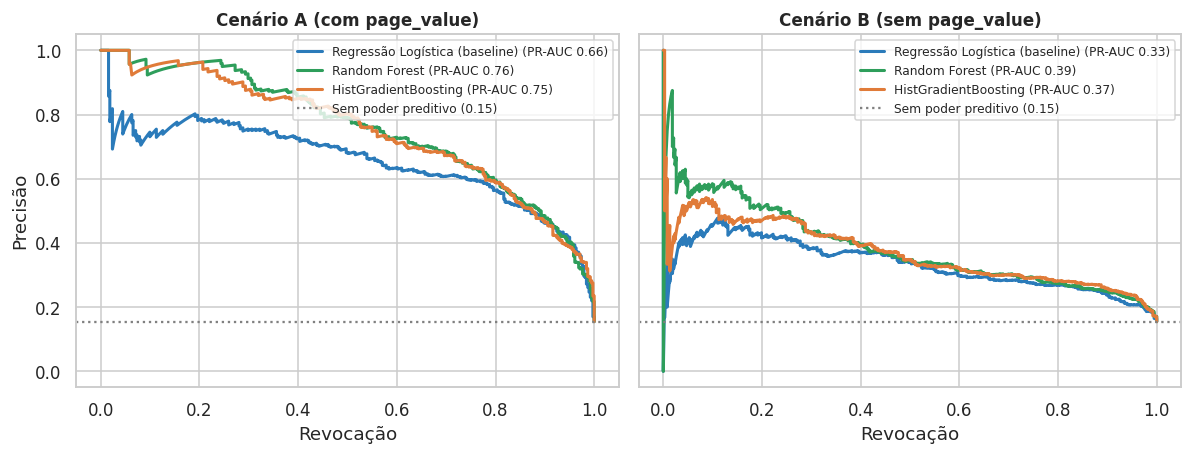

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
cores = {"Dummy (prevalência)": "#AAAAAA", "Regressão Logística (baseline)": "#2B7BBA",
         "Random Forest": "#2E9E5B", "HistGradientBoosting": COR_SIM}
for ax, cen in zip(axes, CENARIOS):
    for nome in MODELOS:
        if nome.startswith("Dummy"):      # score constante: a curva seria uma reta sem significado
            continue
        p = probas[(cen, nome)]
        prec, rec, _ = precision_recall_curve(y_test, p)
        ax.plot(rec, prec, color=cores[nome], lw=2,
                label=f"{nome} (PR-AUC {average_precision_score(y_test, p):.2f})")
    ax.axhline(y_test.mean(), ls=":", color="gray", label=f"Sem poder preditivo ({y_test.mean():.2f})")
    ax.set_xlabel("Revocação")
    ax.set_title(f"Cenário {cen}")
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("Precisão")
plt.tight_layout()
plt.show()

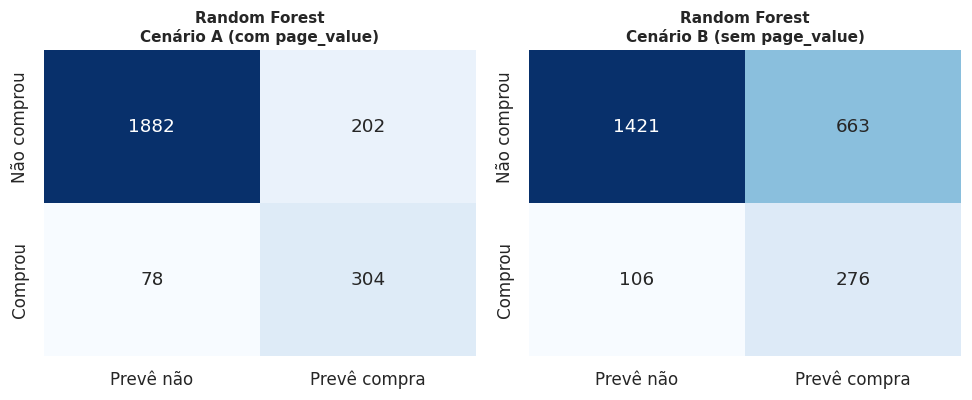

In [55]:
# Melhor modelo de cada cenário (por PR-AUC no teste) e matriz de confusão no limiar escolhido no treino
melhor_por_cenario = {cen: resultados.loc[cen, "PR-AUC"].drop("Dummy (prevalência)").idxmax() for cen in CENARIOS}

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (cen, nome) in zip(axes, melhor_por_cenario.items()):
    pred = (probas[(cen, nome)] >= limiares[(cen, nome)]).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Prevê não", "Prevê compra"], yticklabels=["Não comprou", "Comprou"])
    ax.set_title(f"{nome}\nCenário {cen}", fontsize=10)
plt.tight_layout()
plt.show()

### Quais variáveis mais pesam nas previsões?

Importância por **permutação** (queda na PR-AUC quando uma variável é embaralhada), calculada no teste apenas para
**interpretar** os modelos finais. Nenhuma escolha de modelo ou hiperparâmetro depende dela.

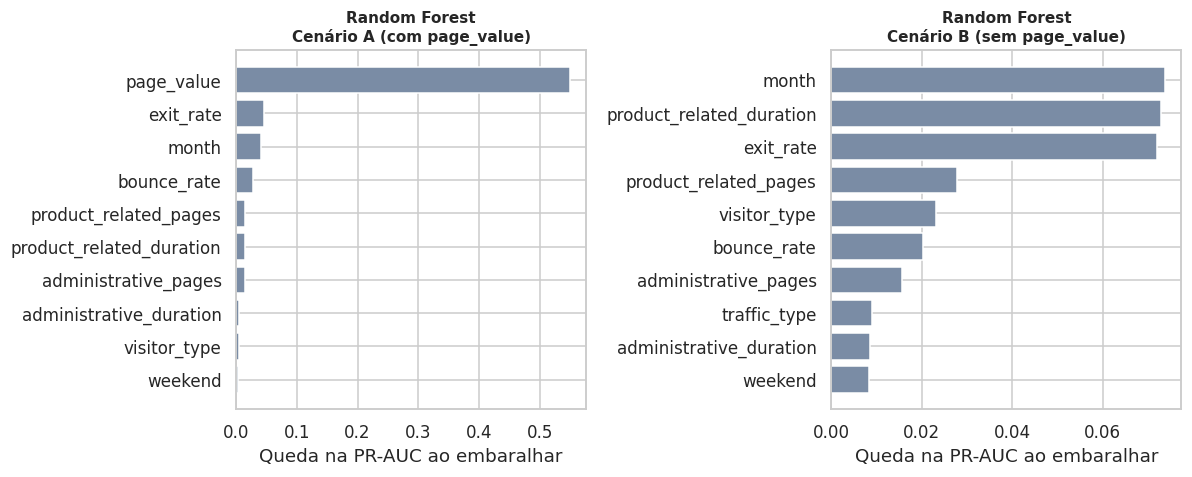

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (cen, nome) in zip(axes, melhor_por_cenario.items()):
    cols = CENARIOS[cen]
    imp = permutation_importance(modelos_finais[(cen, nome)], X_test[cols], y_test, scoring="average_precision",
                                 n_repeats=10, random_state=SEED, n_jobs=1)
    s = pd.Series(imp.importances_mean, index=cols).sort_values().tail(10)
    ax.barh(s.index, s.values, color=COR_NAO)
    ax.set_xlabel("Queda na PR-AUC ao embaralhar")
    ax.set_title(f"{nome}\nCenário {cen}", fontsize=10)
plt.tight_layout()
plt.show()

### Resumo automático dos resultados no teste

In [57]:
base = y_test.mean()
for cen, nome in melhor_por_cenario.items():
    r = resultados.loc[(cen, nome)]
    print(f"Cenário {cen}: melhor modelo = {nome}")
    print(f"   PR-AUC {r['PR-AUC']:.3f} (modelo sem poder preditivo: {base:.3f}, ganho de {r['PR-AUC'] / base:.1f}x) | "
          f"ROC-AUC {r['ROC-AUC']:.3f} | F1 {r['F1']:.3f} | precisão {r['Precisão']:.3f} | revocação {r['Revocação']:.3f}")

a, b = list(melhor_por_cenario.items())
print(f"\nImpacto de page_value (melhor PR-AUC): {resultados.loc[a, 'PR-AUC']:.3f} (com) -> "
      f"{resultados.loc[b, 'PR-AUC']:.3f} (sem), queda de {resultados.loc[a, 'PR-AUC'] - resultados.loc[b, 'PR-AUC']:.3f}")

Cenário A (com page_value): melhor modelo = Random Forest
   PR-AUC 0.759 (modelo sem poder preditivo: 0.155, ganho de 4.9x) | ROC-AUC 0.936 | F1 0.685 | precisão 0.601 | revocação 0.796
Cenário B (sem page_value): melhor modelo = Random Forest
   PR-AUC 0.386 (modelo sem poder preditivo: 0.155, ganho de 2.5x) | ROC-AUC 0.781 | F1 0.418 | precisão 0.294 | revocação 0.723

Impacto de page_value (melhor PR-AUC): 0.759 (com) -> 0.386 (sem), queda de 0.373


### Interpretação dos resultados no contexto do problema

**1. Todos os modelos aprendem algo útil, mas o ganho depende muito do cenário.** O modelo sem poder preditivo tem
PR-AUC igual à prevalência de compras (0,155). No **cenário A** (com `page_value`), o melhor modelo, a Random Forest, chega a
**PR-AUC 0,762** (4,9 vezes a prevalência), **ROC-AUC 0,935** e **F1 0,69** (precisão 0,64, revocação 0,76). No **cenário B**
(sem `page_value`), a melhor também é a Random Forest, com **PR-AUC 0,381** (2,5 vezes a prevalência), **ROC-AUC 0,782** e
**F1 0,42** (precisão 0,32, revocação 0,62).

**2. O `page_value` explica metade do desempenho.** Ao retirá-lo, a PR-AUC cai de 0,762 para 0,381. A importância por
permutação mostra o mesmo: no cenário A, embaralhar `page_value` derruba a PR-AUC em cerca de 0,55, mais de dez vezes o
efeito de qualquer outra variável. No cenário B, o peso se distribui entre `month`, `product_related_duration` e `exit_rate`.
Como `page_value` é calculado a partir de páginas que levaram a compras, o cenário A tende a ser **otimista** e o cenário B é
a estimativa mais realista do que dá para prever só com o comportamento de navegação.

**3. O baseline é bom, mas modelos de árvore superam.** No cenário A, a regressão logística (PR-AUC 0,656) fica cerca de 0,09 a 0,11
abaixo das árvores, o que indica relações não lineares e interações que o modelo linear não captura. No cenário B a
diferença é menor (0,333 contra 0,381 e 0,369). Já **Random Forest e HistGradientBoosting empatam tecnicamente**: a diferença
entre elas (cerca de 0,01) é bem menor que o desvio entre as dobras da validação cruzada (0,01 a 0,04), então não há base
para declarar uma melhor que a outra.

**4. O que isso significa na prática.** Imagine usar o modelo para oferecer um cupom a sessões com alta probabilidade de compra
ou de abandono. No cenário B, com o limiar escolhido, o modelo captura **62% dos compradores**, mas só **32% dos alertas
acertam** (contra 15,5% de acerto ao acaso) e 68% são falsos alarmes. Isso serve para ações **baratas** (um aviso, um
*pop-up*), não para ações caras. No cenário A seriam 76% de compradores capturados e 64% de acerto, mas dependendo de uma
variável cuja disponibilidade no momento da decisão é duvidosa.

**5. Cuidado com `month` no cenário B.** Ele aparece entre as variáveis mais importantes, mas a base cobre um único ano e a separação
treino/teste é aleatória, não temporal. O modelo aprende a sazonalidade deste ano e não há garantia de que ela se repita
em outro período.

## 5. Conclusões, limitações e melhorias

**Conclusões**

- Prever compra a partir de uma sessão é viável, mas só moderadamente quando se descarta o `page_value`: o melhor modelo
  (Random Forest) alcança PR-AUC 0,38 e ROC-AUC 0,78 no teste, cerca de 2,5 vezes a taxa de acerto ao acaso. Com
  `page_value`, a PR-AUC sobe para 0,76, mas essa variável é potencialmente vazada.
- Random Forest e HistGradientBoosting empatam tecnicamente e superam a regressão logística, sobretudo quando há `page_value`.
- Os sinais mais úteis, além de `page_value`, são o engajamento (tempo e páginas em produtos), a taxa de saída, o mês e o tipo de visitante.

**Limitações**

- Uma única loja e cerca de um ano, sem janeiro e abril. A separação é aleatória, não temporal, então a sazonalidade aprendida pode não se repetir.
- Cada linha é uma sessão, não um cliente. Visitantes recorrentes podem aparecer várias vezes, e as dobras da validação cruzada não respeitam esse agrupamento.
- Variáveis anonimizadas (`traffic_type`, `region`, `browser`, `operating_system`) impedem interpretar o significado de cada categoria.
- A disponibilidade de `page_value` no momento da previsão não pôde ser verificada. Por isso os dois cenários foram reportados.
- O limiar de decisão maximiza o F1, sem considerar o custo real de cada tipo de erro.
- Compararam-se poucas configurações (12 a 15 por modelo) com uma única partição de validação cruzada, então diferenças pequenas entre modelos não são conclusivas.
- O teste contém 27 sessões duplicadas, mantidas para preservar a avaliação fornecida.

**Possíveis melhorias**

- Validar com separação temporal (treinar em meses anteriores, testar nos posteriores) e, se houver identificador de cliente, usar `GroupKFold`.
- Repetir a validação cruzada (por exemplo, 5×3) e comparar modelos com testes estatísticos pareados.
- Escolher o limiar por custo/benefício (por exemplo, custo de um cupom contra margem da venda) e calibrar as probabilidades.
- Criar atributos novos, como razão tempo/página, total de páginas e indicador de saída muito baixa, e testar *target encoding* para `traffic_type`.
- Experimentar outros modelos (XGBoost, LightGBM) e explicações com SHAP.
- Confirmar com a fonte como o `page_value` é calculado, para decidir se ele pode entrar no modelo.